**Install and import the required libraries bold text**

In [2]:
!pip -q install datasets

In [3]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


**Load and explore the TinyStories dataset**

In [4]:
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))
print(train_text[:500])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Training stories: 900
Validation stories: 100
Anna and Ben are friends. They like to play together. Today, they have a task. They have to find a beautiful flower for their teacher.

They walk in the park. They see many flowers. Some are red, some are yellow, some are pink. But they want to find the most beautiful flower of all.

They see a big hill. They think maybe there is a beautiful flower on top of the hill. They run to the hill. They jump over rocks and sticks. They climb up the hill. They are tired, but they are happy.

They reach th


**Preprocess the text** - This experiment uses character-level tokenization: each unique character receives an integer ID.

In [5]:
chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(text):
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

train_data = torch.tensor(
    encode(train_text), dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text), dtype=torch.long
)

print("Vocabulary size:", vocab_size)
print("Encoded sample:", encode("Once upon a time")[:10])
print("Decoded sample:", decode(encode("Once upon a time")))

Vocabulary size: 75
Encoded sample: [31, 56, 45, 47, 1, 63, 58, 57, 56, 1]
Decoded sample: Once upon a time


**Build the Transformer architecture** - Defined a tiny character-level Transformer with token embeddings, positional embeddings, two Transformer encoder layers, two attention heads, feed-forward networks, and a linear output layer. PyTorch’s encoder layers include residual connections and layer normalization. A causal mask blocks attention to future characters.

In [6]:
class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, 64)
        self.pos_emb = nn.Embedding(64, 64)

        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=2,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            activation="gelu"
        )

        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.lm_head = nn.Linear(64, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        positions = torch.arange(T, device=idx.device)

        x = self.token_emb(idx) + self.pos_emb(positions)

        # Prevent each position from seeing future characters
        mask = torch.triu(
            torch.ones(
                T, T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        x = self.blocks(x, mask=mask)

        return self.lm_head(x)


model = TinyTransformer().to(device)

print(
    "Number of parameters:",
    sum(p.numel() for p in model.parameters())
)

Number of parameters: 80715


**Prepare training data** - Created random batches of 64-character input sequences and targets shifted one character forward. The model learns to predict the next character from the preceding characters.

In [7]:
block_size = 64
batch_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)


x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


**Initialize and train the model**

In [16]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

train_history = []
val_history = []

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []

    for _ in range(num_batches):
        x, y = get_batch(split_name)
        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        losses.append(loss.item())

    model.train()
    return sum(losses) / len(losses)


for epoch in range(15):
    model.train()
    total_loss = 0.0

    for step in range(100):
        x, y = get_batch("train")

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / 100
    val_loss = evaluate("val", num_batches=10)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if epoch == 4:
        epoch_5_weights = {
            name: weight.detach().cpu().clone()
            for name, weight in model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f} | "
        f"Validation loss: {val_loss:.3f}"
    )

Epoch 01 | Train loss: 1.576 | Validation loss: 1.581
Epoch 02 | Train loss: 1.550 | Validation loss: 1.559
Epoch 03 | Train loss: 1.541 | Validation loss: 1.554
Epoch 04 | Train loss: 1.524 | Validation loss: 1.527
Epoch 05 | Train loss: 1.518 | Validation loss: 1.531
Epoch 06 | Train loss: 1.495 | Validation loss: 1.516
Epoch 07 | Train loss: 1.484 | Validation loss: 1.486
Epoch 08 | Train loss: 1.476 | Validation loss: 1.506
Epoch 09 | Train loss: 1.473 | Validation loss: 1.454
Epoch 10 | Train loss: 1.466 | Validation loss: 1.466
Epoch 11 | Train loss: 1.452 | Validation loss: 1.477
Epoch 12 | Train loss: 1.433 | Validation loss: 1.462
Epoch 13 | Train loss: 1.441 | Validation loss: 1.449
Epoch 14 | Train loss: 1.421 | Validation loss: 1.431
Epoch 15 | Train loss: 1.420 | Validation loss: 1.436


**Monitor training** - Plotted training and validation cross-entropy losses across epochs. Falling losses indicate improved next-character prediction; a growing gap between training and validation loss may indicate overfitting.

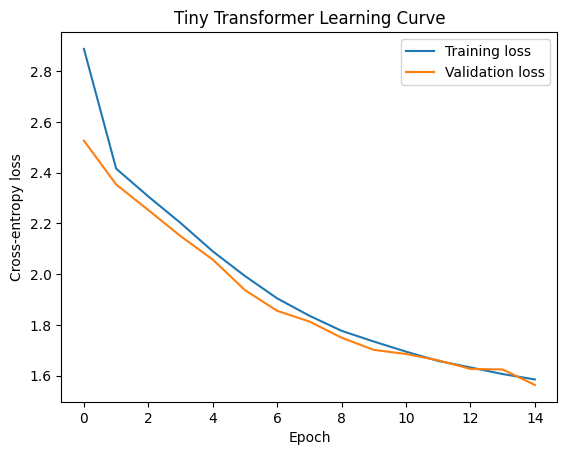

In [9]:
import matplotlib.pyplot as plt

plt.plot(train_history, label="Training loss")
plt.plot(val_history, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer Learning Curve")
plt.legend()
plt.show()

**Evaluate the model** - Estimated validation cross-entropy loss on 20 randomly sampled batches and calculated perplexity as the exponential of loss. Lower perplexity indicates better next-character predictions.

In [10]:
val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.2f}")

Validation loss: 1.5889
Validation perplexity: 4.90


**Generate stories** - Added the text-generation function missing from the supplied script. It predicts the next character repeatedly from a starting prompt, using only the last 64 characters as context. The prompt must use characters found in the training vocabulary.

In [11]:
@torch.no_grad()
def generate(prompt, max_new_chars=200, temperature=1.0):
    if not prompt or any(ch not in stoi for ch in prompt):
        raise ValueError("Prompt must be non-empty and contain only vocabulary characters.")
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    was_training = model.training
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_chars):
        idx_cond = idx[:, -block_size:]
        logits = model(idx_cond)[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, next_id), dim=1)
    if was_training:
        model.train()
    return decode(idx[0].tolist())

print(generate("Once upon a time", max_new_chars=200))

Once upon a time,

A fas that?" Lily say.
One dope. Whaty, the lew a ly. The stit hilyse the said, "It's Lily have fineare. Sare, the likipped secialoy. She fill a scan twere so it is thank and felt and see squinden 


 **Experiment with model settings** - Both samples used the same prompt, “Once upon a time.”
Validation loss dropped from **1.531** at 5 epochs to **1.436** at 15 epochs.

The 5-epoch sample produced “Lily sayy,” while the 15-epoch sample
produced “Tim says.” Both stories were hard to follow.

In [17]:
prompt = "Once upon a time"

print(f"Epoch 5 validation loss:  {val_history[4]:.3f}")
print(f"Epoch 15 validation loss: {val_history[14]:.3f}")

torch.manual_seed(42)
story_15 = generate(prompt, max_new_chars=200, temperature=1.0)

# Keep the 15-epoch weights so Task 11 can save the final model.
epoch_15_weights = {
    name: weight.detach().cpu().clone()
    for name, weight in model.state_dict().items()
}

model.load_state_dict(epoch_5_weights)
try:
    torch.manual_seed(42)
    story_5 = generate(prompt, max_new_chars=200, temperature=1.0)
finally:
    model.load_state_dict(epoch_15_weights)

print("\nStory after 5 epochs")
print(story_5)

print("\nStory after 15 epochs")
print(story_15)

Epoch 5 validation loss:  1.531
Epoch 15 validation loss: 1.436

Story after 5 epochs
Once upon a time, there blook?" Lily sayy, in the him gay!â€

Flowday, it were healllyse and said, "I day, all said, to hem a gruard her is couse. He you little day. The was closit it for all. But he stare there deca

Story after 15 epochs
Once upon a time, there bloon?" 

Tim says, Sara trive and the cowday, it who little beep come. Lily cralled and Sam to heave arears her is could. He you little said, "I was close it clorril and Jacked and shoutsing 


**Build a Gradio chat window** - Used the original Gradio chat interface to accept user prompts and display the Transformer’s generated continuation. The missing generate function is now provided in Task 9. This is a text-continuation demo, not an instruction-tuned conversational chatbot.

In [18]:
!pip -q install gradio

import gradio as gr

def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a message."

    if "stoi" not in globals() or "generate" not in globals():
        return "Error: Please run the cells that define stoi and generate first."

    supported = "".join(ch for ch in message if ch in stoi)

    if not supported:
        return "Please try text using characters in the training dataset."

    try:
        return generate(supported, max_new_chars=100)
    except Exception as e:
        return f"Text generation failed: {type(e).__name__}: {e}"

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer Chatbot",
    description="A language model trained from scratch in our LLM class."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6665422d0461ee6d55.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**Save the trained model**

In [19]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "chars": chars,
    "vocab_size": vocab_size,
    "config": {
        "embedding_dim": 64,
        "num_heads": 2,
        "num_layers": 2,
        "block_size": 64,
        "feedforward_dim": 128
    }
}

torch.save(checkpoint, "tiny_transformer.pt")

print("Model saved successfully!")

from google.colab import files

files.download("tiny_transformer.pt")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>